# Task 3 — Distributions and relationships (`penguins.csv`)

**Data:** 344 penguins from 3 species on 3 islands. Columns: `species`, `island`, `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`, `sex`.

**Plan:** (0) find the missing values and decide what to do with them, (1) distribution of body mass, (2) the same split by species, (3) bill length vs bill depth (Simpson's paradox), (4) mean body mass by species and sex.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.ticker import FuncFormatter

candidates = [Path(p) for p in ["penguins.csv", "data/penguins.csv", "../data/penguins.csv", "../penguins.csv"]]
path = next((p for p in candidates if p.exists()), None) or next(Path("..").rglob("penguins.csv"))
df = pd.read_csv(path)
assert df.shape[0] == 344, df.shape
print(f"Loaded {path}: {df.shape[0]} rows, columns = {list(df.columns)}")

# Colours: one colour per species, used for species in every chart. Neutral grey = "all penguins" (no species split).
SURFACE, INK, INK2, GRID, GREY = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3", "#9a9993"
SPECIES = ["Adelie", "Chinstrap", "Gentoo"]
COL = dict(zip(SPECIES, ["#2a78d6", "#eb6834", "#1baf7a"]))   # fixed order, checked for colour-blind separation

def clean_style():
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
        "axes.edgecolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.7,
        "axes.axisbelow": True, "font.size": 10, "text.parse_math": False,
    })
clean_style()

Loaded penguins.csv: 344 rows, columns = ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


## Step 0 — Find the missing values first

In [2]:
measures = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print("Missing values per column:")
print(df.isna().sum().to_string())

no_measurements = df[df[measures].isna().all(axis=1)]
no_sex = df[df["sex"].isna()]
print(f"\nPenguins with all four measurements missing: {len(no_measurements)}  (row index {no_measurements.index.tolist()})")
print(f"Penguins with sex missing: {len(no_sex)}  of which also have no measurements: {len(no_sex.index.intersection(no_measurements.index))}")
print(f"=> measurements present but sex unknown: {len(no_sex) - len(no_measurements)}")
no_sex

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11

Penguins with all four measurements missing: 2  (row index [3, 271])
Penguins with sex missing: 11  of which also have no measurements: 2
=> measurements present but sex unknown: 9


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
268,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN


### Decision
- **The 2 penguins with no measurements (rows 3 and 271)** have nothing to plot, so they are **excluded from every chart**. That leaves 342 penguins in Steps 1–3.
- **The 11 penguins with missing `sex`:** these include the 2 above, so 9 penguins have measurements but an unknown sex. Steps 1–3 never use `sex`, so I **keep those 9** there. Step 4 splits by sex, so there I **exclude them** (333 penguins). I do **not guess** (impute) their sex: guessing would feed my own assumption into a chart about sex differences.
- Every chart's footnote states how many penguins are shown and who was excluded.

In [3]:
pen = df.dropna(subset=measures).copy()                 # 342 penguins with measurements (Steps 1-3)
pen_sex = pen.dropna(subset=["sex"]).copy()            # 333 penguins with a known sex (Step 4)
print(len(pen), len(pen_sex))
print(pen["species"].value_counts().reindex(SPECIES).to_dict())

342 333
{'Adelie': 151, 'Chinstrap': 68, 'Gentoo': 123}


## Step 1 — Distribution of body mass

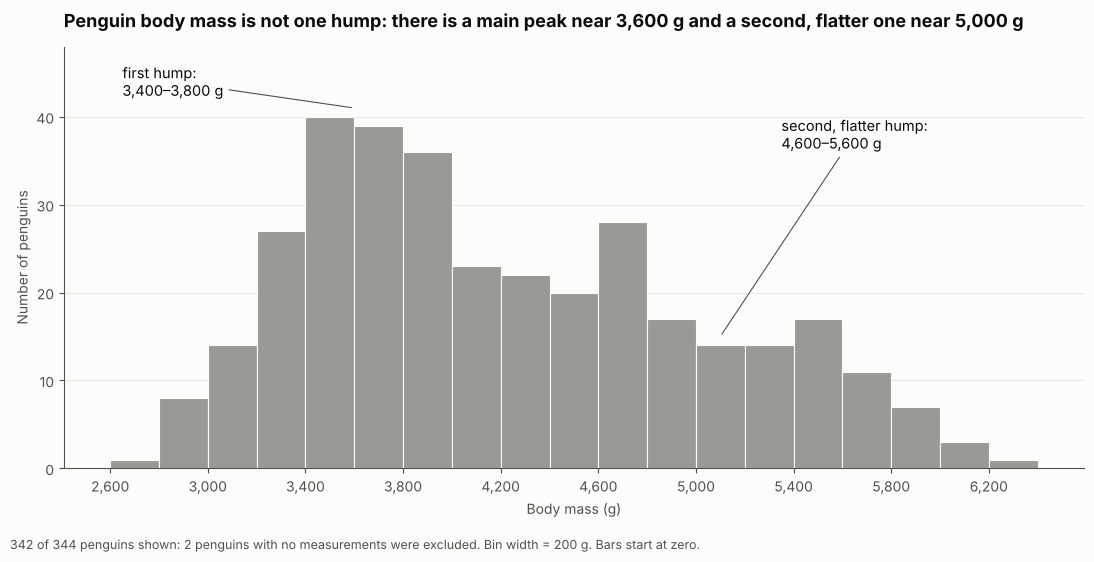

mean = 4,202 g, median = 4,050 g, min = 2,700, max = 6,300


In [4]:
bins = np.arange(2600, 6400 + 200, 200)      # 200 g bins, the same in Steps 1 and 2
mass = pen["body_mass_g"]

fig, ax = plt.subplots(figsize=(11, 5.6))
ax.hist(mass, bins=bins, color=GREY, edgecolor=SURFACE, linewidth=0.8)
ax.set_xlabel("Body mass (g)"); ax.set_ylabel("Number of penguins")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xticks(range(2600, 6600, 400))

ax.annotate("first hump:\n3,400–3,800 g", xy=(3600, 41), xytext=(2650, 44), ha="left", va="center", fontsize=10.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.annotate("second, flatter hump:\n4,600–5,600 g", xy=(5100, 15), xytext=(5350, 38), ha="left", va="center", fontsize=10.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.set_ylim(0, 48)
ax.set_title("Penguin body mass is not one hump: there is a main peak near 3,600 g and a second, flatter one near 5,000 g",
             loc="left", fontsize=13, fontweight="bold", pad=14)
fig.text(0.01, 0.01,
         f"{len(pen)} of 344 penguins shown: 2 penguins with no measurements were excluded. Bin width = 200 g. Bars start at zero.",
         fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
print(f"mean = {mass.mean():,.0f} g, median = {mass.median():,.0f} g, min = {mass.min():,.0f}, max = {mass.max():,.0f}")

**Why a histogram?** Body mass is one continuous variable, and the question is about the *shape* of its distribution (one hump or more), which is exactly what a histogram shows. A box plot or a mean ± SD bar would hide the shape: both would summarise this data as one number around 4,200 g, a mass that falls in the dip between the two humps (about 22 penguins per 200 g bin, against 40 at the main peak). I used 200 g bins, narrow enough to see structure and wide enough that the bars are not noisy; the y-axis starts at zero because bars encode counts by length. I used one neutral grey, because at this point there is nothing to colour by, and I keep the species colours for when species appear.

**What shape is it?** It is **not a single hump.** There is a tall peak at about 3,400–3,800 g, then a dip around 4,000–4,400 g, then a second, lower and flatter hump from about 4,600 to 5,600 g. It is also right-skewed (mean 4,202 g vs median 4,050 g). That is a sign that two or more different groups are mixed together in the data.

## Step 2 — Split by species

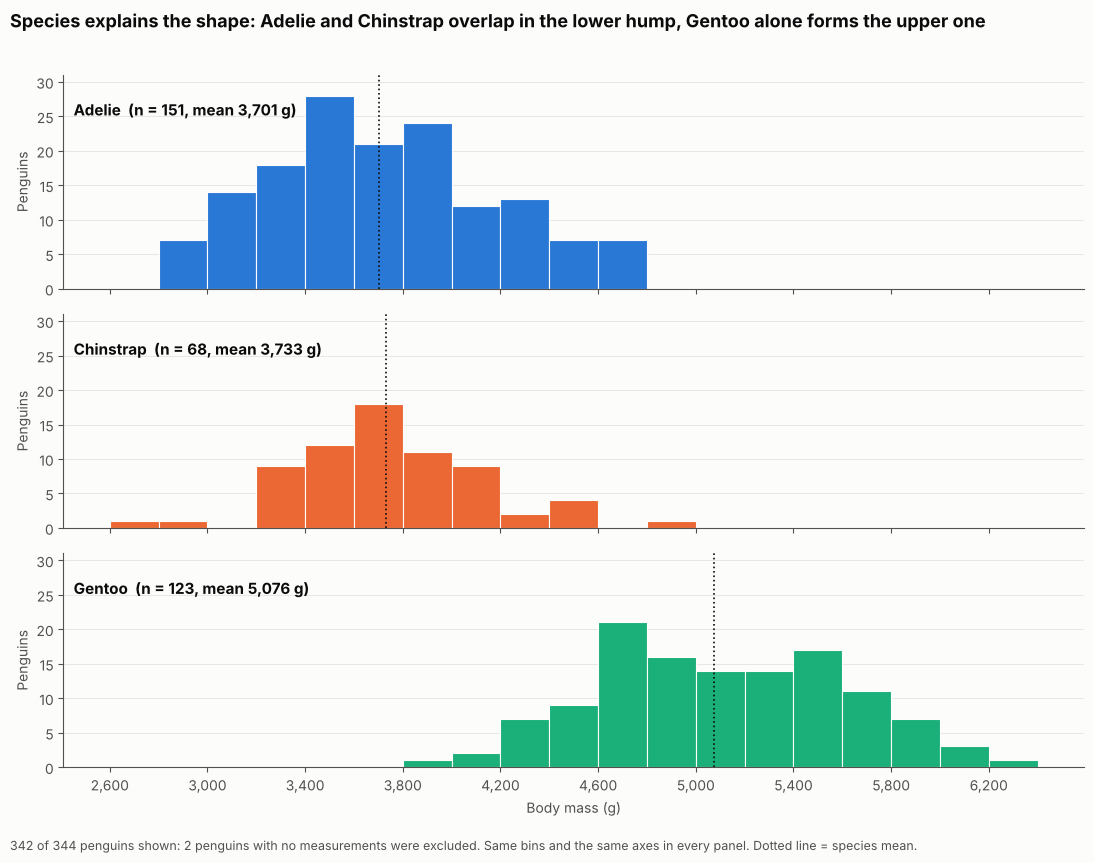

,n,mean,std,min,max
species,,,,,
Adelie,151,3701.0,459.0,2850.0,4775.0
Chinstrap,68,3733.0,384.0,2700.0,4800.0
Gentoo,123,5076.0,504.0,3950.0,6300.0


In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8.6), sharex=True, sharey=True)
for ax, sp in zip(axes, SPECIES):
    d = pen[pen["species"] == sp]["body_mass_g"]
    ax.hist(d, bins=bins, color=COL[sp], edgecolor=SURFACE, linewidth=0.8)
    ax.text(0.01, 0.88, f"{sp}  (n = {len(d)}, mean {d.mean():,.0f} g)", transform=ax.transAxes, ha="left", va="top",
            fontsize=11, color=INK, fontweight="bold")
    ax.axvline(d.mean(), color=INK, lw=1.2, ls=":")
    ax.set_ylabel("Penguins")
axes[-1].set_xlabel("Body mass (g)")
axes[-1].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[-1].set_xticks(range(2600, 6600, 400))
axes[0].set_ylim(0, 31)
fig.suptitle("Species explains the shape: Adelie and Chinstrap overlap in the lower hump, Gentoo alone forms the upper one",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=0.985)
fig.text(0.01, 0.008,
         f"{len(pen)} of 344 penguins shown: 2 penguins with no measurements were excluded. Same bins and the same axes in every panel. "
         "Dotted line = species mean.",
         fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
plt.show()

summary = pen.groupby("species")["body_mass_g"].agg(n="count", mean="mean", std="std", min="min", max="max").round(0)
summary

In [6]:
# How much of the variation in body mass does each grouping explain? (share of total variance, R^2)
def r2(data, by):
    total = ((data["body_mass_g"] - data["body_mass_g"].mean()) ** 2).sum()
    within = sum(((g["body_mass_g"] - g["body_mass_g"].mean()) ** 2).sum() for _, g in data.groupby(by))
    return 1 - within / total
print(f"species alone:        {r2(pen_sex, 'species'):.0%}")
print(f"species and sex:      {r2(pen_sex, ['species', 'sex']):.0%}   (the 333 penguins with a known sex)")

species alone:        67%
species and sex:      85%   (the 333 penguins with a known sex)


**Why this chart?** The same histogram as Step 1, drawn once per species, with identical bins and identical axes in every panel so the three shapes can be compared directly. I stacked the panels instead of overlaying three semi-transparent histograms, because overlapping bars blur Adelie and Chinstrap, which sit almost on top of each other. Colour now has a job (species), it is fixed per species for the rest of this notebook, and each panel is labelled directly, so there is no legend. The dotted line marks each species' mean, which is the one number worth adding.

**Does it explain the shape from Step 1? Mostly, yes.**
- The **second hump is Gentoo.** Gentoo penguins average 5,076 g, and 86% of them weigh more than 4,500 g, against 4% of the other two species.
- The **first hump is Adelie and Chinstrap together.** Their means are almost the same (3,701 g and 3,733 g), so their distributions land on top of each other and form one hump.
- So the "two humps" in Step 1 came from mixing a heavy species with two light ones. Species alone accounts for about two thirds of the variation in body mass.
- **Species does not explain everything.** Each species is still about 1,900–2,400 g wide, and Gentoo is flat on top rather than sharply peaked. That is **sex**: males are heavier than females within each species, and species plus sex together explain about 85% of the variation (Step 4 looks at this).

## Step 3 — Bill length vs bill depth (the important one)

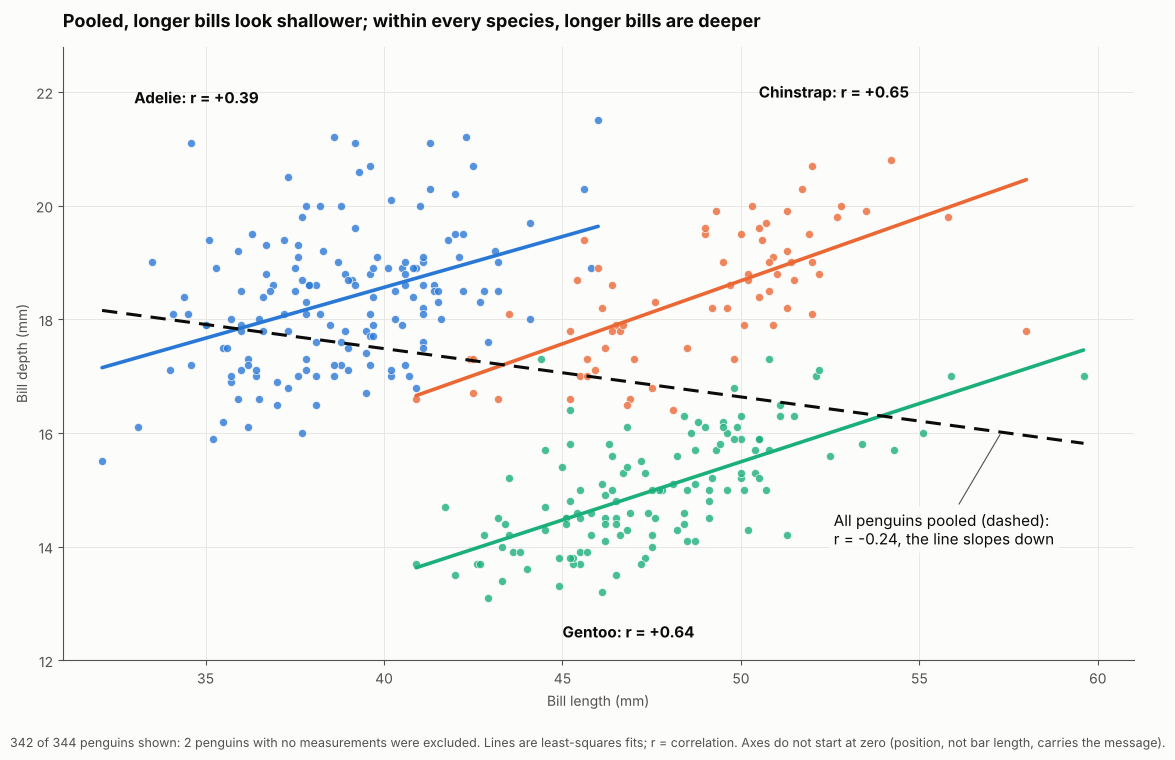

In [7]:
b = pen.copy()
x_all, y_all = b["bill_length_mm"], b["bill_depth_mm"]
r_all = x_all.corr(y_all)
slope_all, icpt_all = np.polyfit(x_all, y_all, 1)

fig, ax = plt.subplots(figsize=(11.5, 7.6))
for sp in SPECIES:
    d = b[b["species"] == sp]
    ax.scatter(d["bill_length_mm"], d["bill_depth_mm"], s=34, color=COL[sp], alpha=0.8, edgecolor=SURFACE, linewidth=0.6, zorder=3)

# trend line for each species (colour = species) and for all penguins pooled (grey, dashed)
for sp in SPECIES:
    d = b[b["species"] == sp]
    s, i = np.polyfit(d["bill_length_mm"], d["bill_depth_mm"], 1)
    xs = np.array([d["bill_length_mm"].min(), d["bill_length_mm"].max()])
    ax.plot(xs, s * xs + i, color=COL[sp], lw=2.6, zorder=4, solid_capstyle="round")
xs = np.array([x_all.min(), x_all.max()])
ax.plot(xs, slope_all * xs + icpt_all, color=INK, lw=2.2, ls=(0, (5, 3)), zorder=5)

# direct labels
r = {sp: b[b["species"] == sp]["bill_length_mm"].corr(b[b["species"] == sp]["bill_depth_mm"]) for sp in SPECIES}
ax.text(33.0, 21.9, f"Adelie: r = +{r['Adelie']:.2f}", ha="left", va="center", fontsize=11, color=INK, fontweight="bold")
ax.text(50.5, 22.0, f"Chinstrap: r = +{r['Chinstrap']:.2f}", ha="left", va="center", fontsize=11, color=INK, fontweight="bold")
ax.text(45.0, 12.5, f"Gentoo: r = +{r['Gentoo']:.2f}", ha="left", va="center", fontsize=11, color=INK, fontweight="bold")
ax.annotate(f"All penguins pooled (dashed):\nr = {r_all:.2f}, the line slopes down",
            xy=(57.3, slope_all * 57.3 + icpt_all), xytext=(52.6, 14.3), ha="left", va="center", fontsize=11, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8), bbox=dict(boxstyle="round,pad=0.3", fc=SURFACE, ec="none", alpha=0.9))

ax.set_xlim(31, 61); ax.set_ylim(12, 22.8)
ax.set_xlabel("Bill length (mm)"); ax.set_ylabel("Bill depth (mm)")
ax.grid(axis="x", color=GRID, linewidth=0.7)
ax.set_title("Pooled, longer bills look shallower; within every species, longer bills are deeper",
             loc="left", fontsize=13, fontweight="bold", pad=14)
fig.text(0.01, 0.01,
         f"{len(b)} of 344 penguins shown: 2 penguins with no measurements were excluded. Lines are least-squares fits; "
         "r = correlation. Axes do not start at zero (position, not bar length, carries the message).",
         fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [8]:
# Evidence for the explanation: correlations and group means
rows = [("All penguins pooled", b)] + [(sp, b[b["species"] == sp]) for sp in SPECIES]
rows += [("Adelie + Chinstrap pooled", b[b["species"] != "Gentoo"]),
         ("Chinstrap + Gentoo pooled", b[b["species"] != "Adelie"]),
         ("Adelie + Gentoo pooled", b[b["species"] != "Chinstrap"])]
corr_table = pd.DataFrame({
    "n": [len(d) for _, d in rows],
    "r (bill length vs depth)": [d["bill_length_mm"].corr(d["bill_depth_mm"]) for _, d in rows],
    "slope (mm depth per mm length)": [np.polyfit(d["bill_length_mm"], d["bill_depth_mm"], 1)[0] for _, d in rows],
}, index=[n for n, _ in rows]).round(2)
display(corr_table)
display(b.groupby("species")[["bill_length_mm", "bill_depth_mm"]].mean().round(1).rename(columns=lambda c: "mean " + c))

,n,r (bill length vs depth),slope (mm depth per mm length)
All penguins pooled,342,-0.24,-0.09
Adelie,151,0.39,0.18
Chinstrap,68,0.65,0.22
Gentoo,123,0.64,0.20
Adelie + Chinstrap pooled,219,0.28,0.06
Chinstrap + Gentoo pooled,191,0.50,0.30
Adelie + Gentoo pooled,274,-0.55,-0.21


,mean bill_length_mm,mean bill_depth_mm
species,,
Adelie,38.8,18.3
Chinstrap,48.8,18.4
Gentoo,47.5,15.0


**Why a scatter plot, coloured by species?** Bill length and bill depth are two continuous variables and the question is how they relate, so a scatter plot (one dot per penguin) is the natural form. Colour has a job: it identifies species, using the same colours as in Step 2, and the species are labelled directly on the chart instead of in a legend. I added a trend line per species (in its own colour) and one dashed pooled line (neutral dark), because the whole point is the *contrast* between those lines, and the correlation `r` is printed on the chart so the reader sees the sign without reading the axes. The dots are semi-transparent so that overlapping points stay visible. A scatter plot's axes do not need to start at zero, since position rather than bar length carries the information, and starting at zero would squash the clusters into a corner.

**What is going on? This is Simpson's paradox.** Treating all 342 penguins as one group, bill length and bill depth are **negatively** related (r = −0.24: longer bills go with shallower bills). But inside **each** species the relationship is **positive** (r = +0.39 for Adelie, +0.65 for Chinstrap, +0.64 for Gentoo): longer bills go with deeper bills. The sign of the trend flips depending on whether you look at the pooled data or at the groups. This effect is called **Simpson's paradox** (also the Yule–Simpson effect): a trend that appears in every subgroup can disappear or even reverse when the groups are combined.

**Why it happens.** The third variable, **species**, differs systematically in *both* measurements, and it hides inside the pooled cloud:
- **Adelie** have short but deep bills (about 38.8 mm long, 18.3 mm deep), while **Gentoo** have long but shallow bills (47.5 mm long, 15.0 mm deep). Chinstrap are long and deep (48.8 mm, 18.4 mm).
- Moving *between* species, especially from Adelie to Gentoo, bills get longer and shallower, which gives a downward slope across the clusters. The table shows that this contrast does most of the damage: pooling only Adelie and Gentoo gives r = −0.55, while pooling the other pairs stays positive.
- Moving *within* a species, a bigger bird just has a bigger bill in both directions (longer and deeper), which gives an upward slope inside every cluster.
- The pooled line therefore measures **which species a penguin belongs to**, not how a bill changes shape. It describes a difference *between* groups, and the within-group relationship points the other way.

**Which result is "right"?** It depends on the question. For "how does bill shape change as an individual bird's bill gets bigger?" the within-species positive trend is the meaningful one. The pooled negative trend is only correct as a statement about this particular mixture of three species. The only way to see that is to plot the groups separately, and this is the best argument for always splitting by the obvious grouping variable: the summary number (r = −0.24) was calculated correctly and was still misleading.

## Step 4 — Average body mass by species and sex

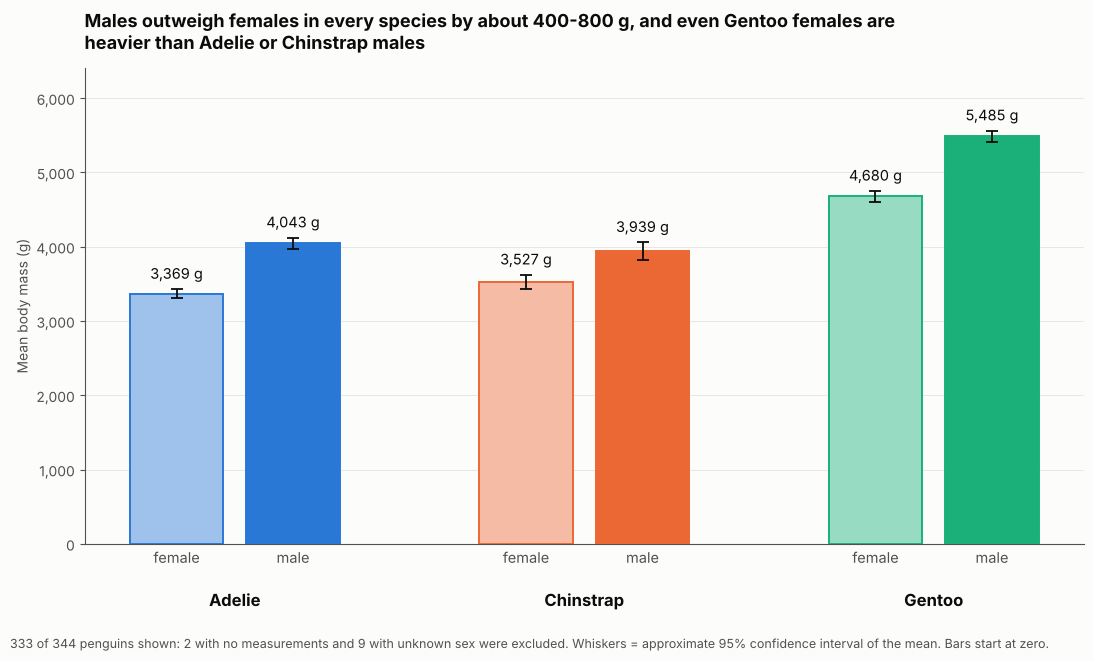

,species,sex,count,mean,std,ci95
0,Adelie,female,73,3369.0,269.0,62.0
1,Adelie,male,73,4043.0,347.0,80.0
2,Chinstrap,female,34,3527.0,285.0,96.0
3,Chinstrap,male,34,3939.0,362.0,122.0
4,Gentoo,female,58,4680.0,282.0,72.0
5,Gentoo,male,61,5485.0,313.0,79.0


In [9]:
g = (pen_sex.groupby(["species", "sex"])["body_mass_g"].agg(["mean", "std", "count"]).reset_index())
g["ci95"] = 1.96 * g["std"] / np.sqrt(g["count"])        # approximate 95% confidence interval of the mean
g["gap"] = g.groupby("species")["mean"].transform(lambda s: s.max() - s.min())

def tint(c, amount=0.55):          # lighter version of a colour, used for females
    return tuple(v + (1 - v) * amount for v in to_rgb(c))

fig, ax = plt.subplots(figsize=(11, 6.6))
bar_w, group_gap = 0.8, 1.0
xt, xl = [], []
for gi, sp in enumerate(SPECIES):
    for si, sex in enumerate(["female", "male"]):
        row = g[(g["species"] == sp) & (g["sex"] == sex)].iloc[0]
        x = gi * (2 + group_gap) + si
        face = tint(COL[sp]) if sex == "female" else COL[sp]
        ax.bar(x, row["mean"], width=bar_w, color=face, edgecolor=COL[sp], linewidth=1.4, zorder=3)
        ax.errorbar(x, row["mean"], yerr=row["ci95"], color=INK, capsize=4, lw=1.3, capthick=1.3, zorder=4)
        ax.text(x, row["mean"] + row["ci95"] + 90, f"{row['mean']:,.0f} g", ha="center", va="bottom", fontsize=10.5, color=INK)
        xt.append(x); xl.append(sex)
ax.set_xticks(xt); ax.set_xticklabels(xl, fontsize=10.5)
for gi, sp in enumerate(SPECIES):
    ax.text(gi * (2 + group_gap) + 0.5, -620, sp, ha="center", va="top", fontsize=12, fontweight="bold", color=INK)
ax.set_ylim(0, 6400)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylabel("Mean body mass (g)")
ax.tick_params(axis="x", length=0)
ax.set_title("Males outweigh females in every species by about 400-800 g, and even Gentoo females are\nheavier than Adelie or Chinstrap males",
             loc="left", fontsize=13, fontweight="bold", pad=14)
fig.text(0.01, 0.01,
         f"{len(pen_sex)} of 344 penguins shown: 2 with no measurements and 9 with unknown sex were excluded. "
         "Whiskers = approximate 95% confidence interval of the mean. Bars start at zero.",
         fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

g[["species", "sex", "count", "mean", "std", "ci95"]].round(0)

**Why grouped bars?** Here the question is a comparison of **averages** across two categorical variables (species and sex), and body mass has a meaningful zero, so bars are the right form: bar length is the value, which is why the y-axis **starts at zero** and the bars are not truncated. I grouped by species and put the two sexes side by side, because the comparisons I care about most are female vs male *within* a species (adjacent bars) and species vs species. The colour is the species (as in Steps 2 and 3); sex is shown by a **solid** bar (male) versus a **light tint** of the same colour (female), and each bar is also labelled by sex and by its value, so the chart does not depend on colour alone. The thin whiskers show the approximate 95% confidence interval of each mean, so the reader can see that the gaps between groups are much larger than the uncertainty in the means. I did not average over sex or over species: pooling would hide the very differences the chart is about, which is the lesson of Step 3 again.

**What it shows.** Males are heavier than females in all three species: by about 674 g for Adelie, 412 g for Chinstrap and 805 g for Gentoo. Gentoo are the heaviest group of either sex, and the Gentoo *females* (4,680 g) are heavier than the Adelie *males* (4,043 g) and the Chinstrap *males* (3,939 g). This also finishes the story from Step 2: the leftover spread inside each species is largely the male–female difference.